# Soal-soal UTS 2.1

## Nomor 1. Tentukan 2 Periode waktu sebagai filter dari data interaksi

Periode data dibagi menjadi dua, yaitu periode pertama (P1) sebagai data training dan periode kedua (P2) sebagai data testing. P1 menggunakan data dengan tanggal datetime mulai 3 Juni 2015 hingga sebelum 24 Juni 2015, sedangkan P2 menggunakan data mulai 2 Juli 2015 hingga sebelum 17 Juli 2015. Pemilihan kedua periode tersebut dilakukan untuk memisahkan data berdasarkan rentang waktu yang berbeda, sehingga P1 digunakan untuk data training dan P2 digunakan untuk data testing.

## Nomor 2. Tetapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan di csv.

In [44]:
import pandas as pd

df = pd.read_csv('events.csv')
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

# P1 (Training)
df_p1 = df[
    (df['datetime'] >= '2015-06-03') &
    (df['datetime'] <= '2015-06-24')
]

# P2 (Testing)
df_p2 = df[
    (df['datetime'] >= '2015-07-02') &
    (df['datetime'] <= '2015-07-17')
]

# Simpan ke CSV baru
df_p1.to_csv('events_p1.csv', index=False)
df_p2.to_csv('events_p2.csv', index=False)

# Tampilkan informasi periode
print("=== PERIODE TRAINING (P1) ===")
print("Rentang filter :", "3 Juni 2015 - 24 Juni 2015")
print("Tanggal awal   :", df_p1['datetime'].min())
print("Tanggal akhir  :", df_p1['datetime'].max())
print("Jumlah baris   :", len(df_p1))

print("\n=== PERIODE TESTING (P2) ===")
print("Rentang filter :", "2 Juli 2015 - 17 Juli 2015")
print("Tanggal awal   :", df_p2['datetime'].min())
print("Tanggal akhir  :", df_p2['datetime'].max())
print("Jumlah baris   :", len(df_p2))

print("\nFilter selesai!")

=== PERIODE TRAINING (P1) ===
Rentang filter : 3 Juni 2015 - 24 Juni 2015
Tanggal awal   : 2015-06-03 00:00:03.487000
Tanggal akhir  : 2015-06-23 23:59:58.745000
Jumlah baris   : 425051

=== PERIODE TESTING (P2) ===
Rentang filter : 2 Juli 2015 - 17 Juli 2015
Tanggal awal   : 2015-07-02 00:00:00.496000
Tanggal akhir  : 2015-07-16 23:59:59.857000
Jumlah baris   : 334646

Filter selesai!


## Nomor 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [45]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Sirimini")


def import_batch(tx, data):
    cypher = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    WHERE row.event = 'view'
    MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    """
    tx.run(cypher, batch=data)


# Menyiapkan sebagian data periode pertama
sample_df = df_p1.head(5000).copy()

if "datetime" in sample_df.columns:
    sample_df["datetime"] = sample_df["datetime"].astype(str)

records = sample_df.to_dict(orient="records")

print("=== INFORMASI IMPORT DATA ===")
print(f"Jumlah baris yang diproses : {len(records)}")
print(f"Jumlah Visitor unik        : {sample_df['visitorid'].nunique()}")
print(f"Jumlah Item unik           : {sample_df['itemid'].nunique()}")
print("Memulai proses import ke Neo4j...")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        session.write_transaction(import_batch, records)

        print("Import data selesai!")
        print("Label node yang diproses   : Visitor dan Item")
        print("Jenis relasi               : VIEWED")


=== INFORMASI IMPORT DATA ===
Jumlah baris yang diproses : 5000
Jumlah Visitor unik        : 3359
Jumlah Item unik           : 3806
Memulai proses import ke Neo4j...
Import data selesai!
Label node yang diproses   : Visitor dan Item
Jenis relasi               : VIEWED


In [46]:
query = """
MATCH (n)
RETURN labels(n) AS Jenis_Simpul, count(n) AS Jumlah
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        result = session.run(query)

        data = [record.data() for record in result]
        df_nodes = pd.DataFrame(data)

print("=== JUMLAH SIMPUL BERDASARKAN LABEL ===")
display(df_nodes)

=== JUMLAH SIMPUL BERDASARKAN LABEL ===


,Jenis_Simpul,Jumlah
0,[Visitor],3359
1,[Item],3806


Pada tahap ini, dilakukan pembentukan subgraph dari data periode pertama (P1) dengan menggunakan Neo4j dan Python API. Data yang digunakan merupakan 5.000 baris pertama dari data P1. Setiap baris data diproses untuk membentuk simpul `Visitor` dan `Item`, sedangkan relasi `VIEWED` dibuat apabila nilai pada kolom `event` adalah `view`.

Pembentukan subgraph dilakukan menggunakan perintah Cypher yang dijalankan melalui fungsi `import_batch()`. Perintah `UNWIND $batch AS row` digunakan untuk memproses data yang dikirimkan dari Python dalam bentuk kumpulan baris. Selanjutnya, `MERGE (v:Visitor {visitorId: row.visitorid})` digunakan untuk membuat atau mencocokkan simpul `Visitor` berdasarkan identitas pengunjung, sedangkan `MERGE (i:Item {itemId: row.itemid})` digunakan untuk membuat atau mencocokkan simpul `Item` berdasarkan identitas barang. Klausa `WHERE row.event = 'view'` membatasi pembentukan relasi hanya pada interaksi dengan jenis *view*. Relasi tersebut dibentuk menggunakan `MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)` untuk menghubungkan pengunjung dengan barang yang dilihat berdasarkan waktu interaksi.

Setelah proses pembentukan subgraph selesai, dilakukan query Cypher untuk memperoleh komposisi simpul berdasarkan labelnya. Query yang digunakan adalah sebagai berikut:

```cypher
MATCH (n)
RETURN labels(n) AS Jenis_Simpul, count(n) AS Jumlah
```

Perintah `MATCH (n)` digunakan untuk mencocokkan seluruh simpul dalam database yang sedang diakses. Fungsi `labels(n)` mengambil label dari setiap simpul dan menampilkannya dengan nama kolom `Jenis_Simpul`. Sementara itu, `count(n)` digunakan untuk menghitung jumlah simpul dan menampilkannya dengan nama kolom `Jumlah`. Hasil query kemudian diambil melalui Python API menggunakan `session.run()`, diubah menjadi DataFrame dengan Pandas, dan ditampilkan untuk memudahkan interpretasi.

Berdasarkan hasil query, diperoleh sebanyak **3.359 simpul `Visitor`** dan **3.806 simpul `Item`**. Dengan demikian, komposisi subgraph yang terbentuk terdiri atas dua jenis simpul, yaitu `Visitor` sebagai representasi pengunjung dan `Item` sebagai representasi barang. Jumlah simpul `Visitor` menunjukkan banyaknya identitas pengunjung unik yang terbentuk, sedangkan jumlah simpul `Item` menunjukkan banyaknya identitas barang unik yang terbentuk pada subgraph tersebut.

Hasil ini menunjukkan bahwa subgraph memiliki lebih banyak simpul `Item` daripada simpul `Visitor`.

## Nomor 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.metrics.pairwise import cosine_similarity

df_sub = df_p1.head(5000).copy()
df_sub = df_sub.dropna(subset=["visitorid", "itemid"])

print("Jumlah baris data:", len(df_sub))
print("Jumlah User unik :", df_sub["visitorid"].nunique())
print("Jumlah Item unik :", df_sub["itemid"].nunique())

# MEMBENTUK VECTOR SPACE MODELING (VSM) USER

# Baris = User, kolom = Item
# Nilai 1 menunjukkan User pernah berinteraksi dengan Item
user_item_matrix = pd.crosstab(
    df_sub["visitorid"],
    df_sub["itemid"]
)

# Mengubah frekuensi interaksi menjadi nilai biner 0 dan 1
user_item_matrix = (user_item_matrix > 0).astype(int)

print("\n=== KARAKTERISTIK VSM USER ===")
print("Dimensi matriks :", user_item_matrix.ndim)
print("Shape matriks   :", user_item_matrix.shape)
print("Jumlah User     :", user_item_matrix.shape[0])
print("Jumlah Item     :", user_item_matrix.shape[1])
print("Jumlah nilai 1  :", int(user_item_matrix.to_numpy().sum()))
print("Jumlah elemen   :", user_item_matrix.size)

sparsity = 1 - (
    user_item_matrix.to_numpy().sum() / user_item_matrix.size
)

print(f"Sparsity matriks: {sparsity:.4%}")

print("\nContoh matriks VSM User:")
display(user_item_matrix.iloc[:5, :10])

user_similarity = cosine_similarity(user_item_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

print("\n=== MATRIKS SIMILARITY USER ===")
print("Shape similarity:", user_similarity_df.shape)

display(user_similarity_df.iloc[:5, :5])


# Agar graf mudah dibaca, tampilkan maksimal 30 User.
n_plot = min(30, len(user_item_matrix))
plot_users = user_item_matrix.index[:n_plot]

G_user = nx.Graph()
G_user.add_nodes_from(plot_users)

# Hubungkan setiap User dengan 3 User paling mirip
# berdasarkan cosine similarity.
for user_id in plot_users:
    scores = user_similarity_df.loc[user_id].drop(index=user_id)

    # Hanya mempertahankan User dengan similarity > 0
    scores = scores[scores > 0]

    top_neighbors = scores.nlargest(3)

    for neighbor_id, score in top_neighbors.items():
        G_user.add_edge(
            user_id,
            neighbor_id,
            weight=float(score)
        )

print("\n=== KARAKTERISTIK GRAF USER ===")
print("Jumlah node      :", G_user.number_of_nodes())
print("Jumlah edge      :", G_user.number_of_edges())
print("Graf terhubung?  :", nx.is_connected(G_user))



Jumlah baris data: 5000
Jumlah User unik : 3359
Jumlah Item unik : 3806

=== KARAKTERISTIK VSM USER ===
Dimensi matriks : 2
Shape matriks   : (3359, 3806)
Jumlah User     : 3359
Jumlah Item     : 3806
Jumlah nilai 1  : 4307
Jumlah elemen   : 12784354
Sparsity matriks: 99.9663%

Contoh matriks VSM User:


itemid,466,502,516,737,869,1152,1233,1261,1298,1668
visitorid,,,,,,,,,,
283,0,0,0,0,0,0,0,0,0,0
476,0,0,0,0,0,0,0,0,0,0
2219,0,0,0,0,0,0,0,0,0,0
2360,0,0,0,0,0,0,0,0,0,0
3295,0,0,0,0,0,0,0,0,0,0



=== MATRIKS SIMILARITY USER ===
Shape similarity: (3359, 3359)


visitorid,283,476,2219,2360,3295
visitorid,,,,,
283,1.0,0.0,0.0,0.0,0.0
476,0.0,1.0,0.0,0.0,0.0
2219,0.0,0.0,1.0,0.0,0.0
2360,0.0,0.0,0.0,1.0,0.0
3295,0.0,0.0,0.0,0.0,1.0



=== KARAKTERISTIK GRAF USER ===
Jumlah node      : 40
Jumlah edge      : 10
Graf terhubung?  : False


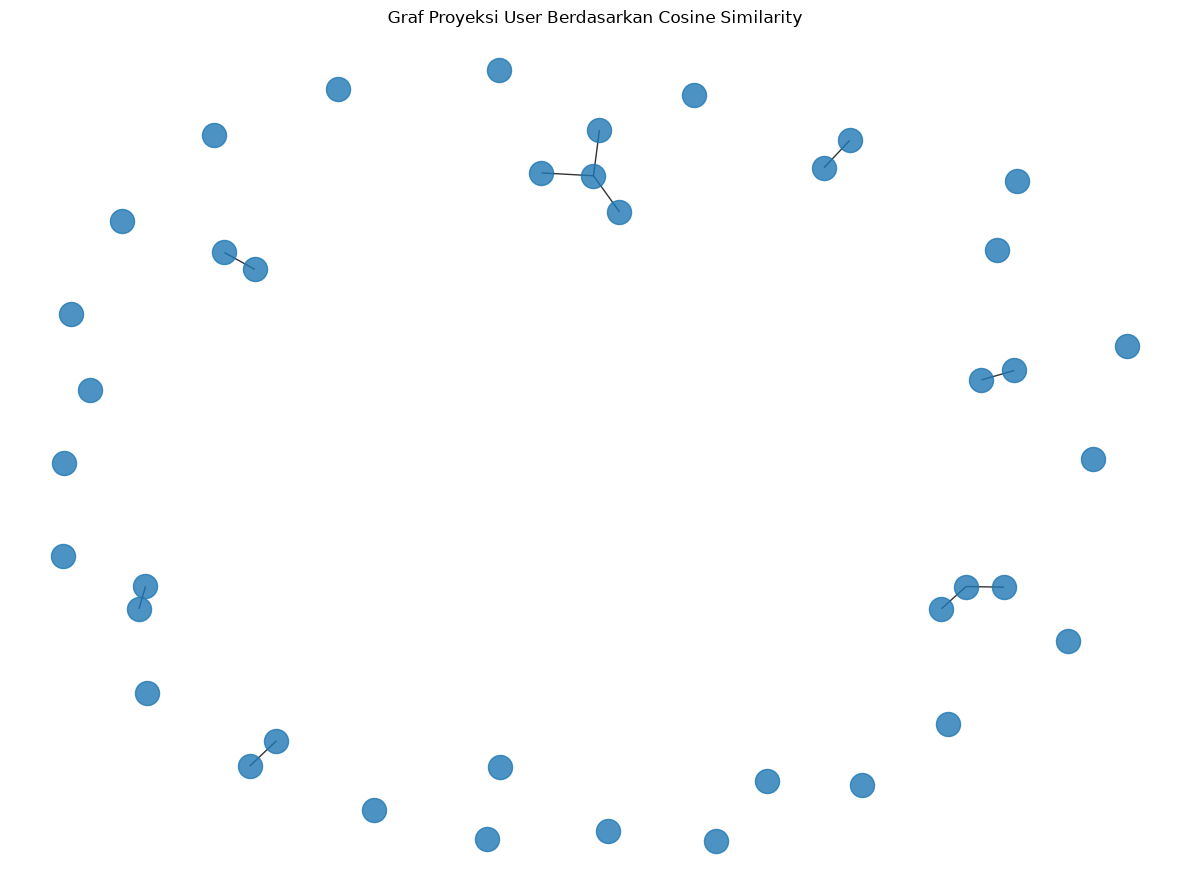

In [48]:
# Visualisasi graf
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    with_labels=False,
    node_size=300,
    alpha=0.8
)

plt.title("Graf Proyeksi User Berdasarkan Cosine Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()

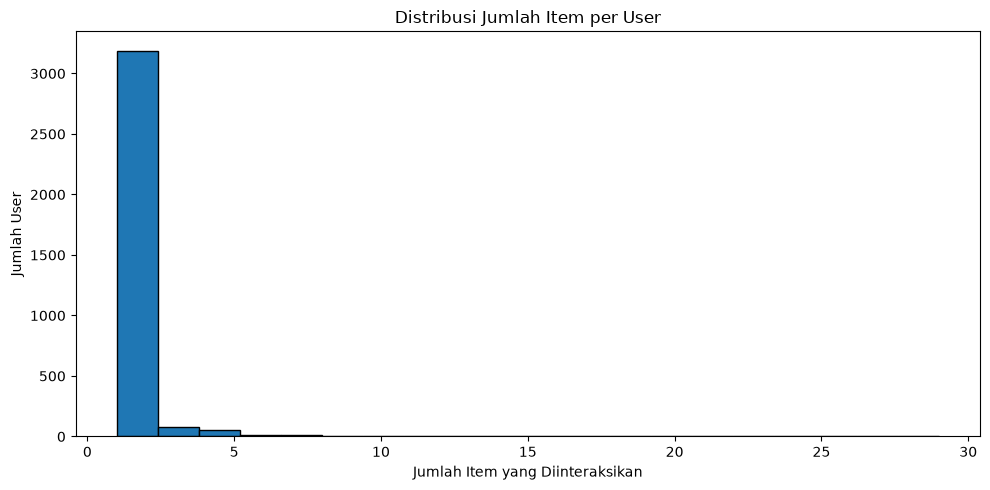

In [49]:
# DISTRIBUSI JUMLAH ITEM YANG DIINTERAKSIKAN USER


user_item_counts = user_item_matrix.sum(axis=1)

plt.figure(figsize=(10, 5))
plt.hist(user_item_counts, bins=20, edgecolor="black")
plt.title("Distribusi Jumlah Item per User")
plt.xlabel("Jumlah Item yang Diinteraksikan")
plt.ylabel("Jumlah User")
plt.tight_layout()
plt.show()


Vector Space Modelling (VSM) dilakukan untuk merepresentasikan setiap User berdasarkan pola interaksinya terhadap Item. Pada analisis ini, User direpresentasikan menggunakan simpul `Visitor`, sedangkan Item direpresentasikan menggunakan identitas `itemid`. Data yang digunakan adalah 5.000 baris pertama dari periode pertama (P1). Penggunaan sebagian data bertujuan untuk membentuk representasi vektor dan melakukan eksplorasi pola interaksi antar-User.

### Pembentukan Matriks VSM User

Pembentukan VSM dilakukan dengan menggunakan fungsi `pd.crosstab()` untuk menghasilkan matriks User–Item. Baris pada matriks merepresentasikan User, sedangkan kolom merepresentasikan Item. Setiap elemen matriks menunjukkan ada atau tidaknya interaksi antara User dan Item. Nilai elemen kemudian diubah menjadi biner, yaitu 1 apabila User pernah berinteraksi dengan Item dan 0 apabila tidak terdapat interaksi.

Berdasarkan hasil pengolahan, diperoleh sebanyak **3.359 User unik** dan **3.806 Item unik**. Dengan demikian, matriks VSM yang terbentuk memiliki dimensi sebanyak 2 dengan `shape` sebesar **(3359, 3806)**. Artinya, matriks tersebut terdiri atas 3.359 baris dan 3.806 kolom. Setiap User direpresentasikan sebagai vektor dengan 3.806 fitur yang menunjukkan pola interaksinya terhadap Item.

Jumlah keseluruhan elemen pada matriks adalah 12.784.354, dengan 4.307 elemen bernilai 1. Nilai tersebut menunjukkan jumlah pasangan User–Item yang memiliki interaksi dalam representasi biner. Sementara itu, elemen bernilai 0 menunjukkan pasangan User–Item yang tidak memiliki interaksi pada sampel data yang digunakan.

### Karakteristik Matriks VSM

Karakteristik dari matriks VSM adalah tingkat *sparsity*, yaitu proporsi elemen matriks yang bernilai 0. Berdasarkan hasil perhitungan, diperoleh nilai *sparsity* sebesar **99,9663%**. Nilai tersebut menunjukkan bahwa hampir seluruh pasangan User–Item dalam matriks tidak memiliki interaksi.

Tingginya nilai *sparsity* berkaitan dengan pola interaksi pada data yang tidak tersebar secara merata. Sebagian besar User hanya berinteraksi dengan sedikit Item dibandingkan dengan jumlah keseluruhan Item yang tersedia pada sampel. Kondisi tersebut juga terlihat pada histogram distribusi jumlah Item yang diinteraksikan oleh setiap User. Histogram menunjukkan bahwa mayoritas User berinteraksi dengan sedikit Item, sedangkan hanya sebagian kecil User yang berinteraksi dengan lebih banyak Item.

### Perhitungan Cosine Similarity Antar-User

Setelah matriks VSM terbentuk, dilakukan perhitungan kemiripan antar-User menggunakan metode *cosine similarity*. Metode ini digunakan untuk mengukur kemiripan antara dua vektor berdasarkan sudut di antara keduanya. Pada representasi biner User–Item, kemiripan akan meningkat apabila dua User memiliki Item yang sama dalam pola interaksinya.

Perhitungan tersebut menghasilkan matriks similarity dengan `shape` sebesar **(3359, 3359)**. Matriks ini membandingkan setiap User dengan seluruh User lainnya. Nilai cosine similarity berkisar antara 0 dan 1 karena elemen matriks VSM bersifat nonnegatif. Nilai yang mendekati 1 menunjukkan pola interaksi yang semakin mirip, sedangkan nilai 0 menunjukkan bahwa kedua User tidak memiliki Item yang sama dalam representasi vektornya. Nilai diagonal sebesar 1 menunjukkan bahwa setiap User memiliki kemiripan sempurna dengan dirinya sendiri.

Berdasarkan contoh hasil matriks similarity, beberapa pasangan User memiliki nilai kemiripan 0. Hal tersebut sejalan dengan tingginya nilai *sparsity* pada matriks VSM, karena banyak User tidak memiliki kesamaan Item dengan User lainnya.

### Visualisasi Graf Proyeksi User Menggunakan NetworkX

Simpul merepresentasikan User, sedangkan sisi merepresentasikan hubungan antara dua User yang memiliki nilai cosine similarity positif. Agar visualisasi mudah dibaca, graf hanya menampilkan **40 User**, meskipun matriks VSM dan matriks similarity dihitung berdasarkan seluruh 3.359 User pada sampel data.

Pembentukan graf dilakukan dengan memilih hingga tiga tetangga teratas untuk setiap User berdasarkan nilai cosine similarity, dengan syarat nilai kemiripan lebih besar dari 0. Berdasarkan hasil visualisasi, graf terdiri atas **40 simpul dan 10 sisi**. Jumlah sisi yang relatif sedikit menunjukkan bahwa hanya sebagian pasangan User dalam kelompok yang divisualisasikan memiliki kemiripan positif dan terpilih sebagai tetangga teratas.

Hasil pemeriksaan graf menunjukkan bahwa graf tidak terhubung (*disconnected graph*). Artinya, tidak semua simpul memiliki jalur yang menghubungkannya dengan simpul lainnya. Beberapa User membentuk kelompok kecil, sedangkan User lainnya berdiri sendiri karena tidak ditemukan hubungan kemiripan positif yang masuk ke dalam graf berdasarkan aturan pembentukan sisi tersebut.

## Nomor 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!     



=== KARAKTERISTIK VSM ITEM ===
Dimensi matriks : 2
Shape matriks   : (3806, 3359)
Jumlah Item     : 3806
Jumlah User     : 3359
Jumlah nilai 1  : 4307
Jumlah elemen   : 12784354
Sparsity matriks: 99.9663%

Contoh matriks VSM Item:


visitorid,283,476,2219,2360,3295,3952,4289,4458,5334,5967
itemid,,,,,,,,,,
466,0,0,0,0,0,0,0,0,0,0
502,0,0,0,0,0,0,0,0,0,0
516,0,0,0,0,0,0,0,0,0,0
737,0,0,0,0,0,0,0,0,0,0
869,0,0,0,0,0,0,0,0,0,0



=== MATRIKS SIMILARITY ITEM ===
Shape similarity: (3806, 3806)


itemid,466,502,516,737,869
itemid,,,,,
466,1.0,0.0,0.0,0.0,0.0
502,0.0,1.0,0.0,0.0,0.0
516,0.0,0.0,1.0,0.0,0.0
737,0.0,0.0,0.0,1.0,0.0
869,0.0,0.0,0.0,0.0,1.0



=== KARAKTERISTIK GRAF ITEM ===
Jumlah node     : 74
Jumlah edge     : 35
Graf terhubung? : False


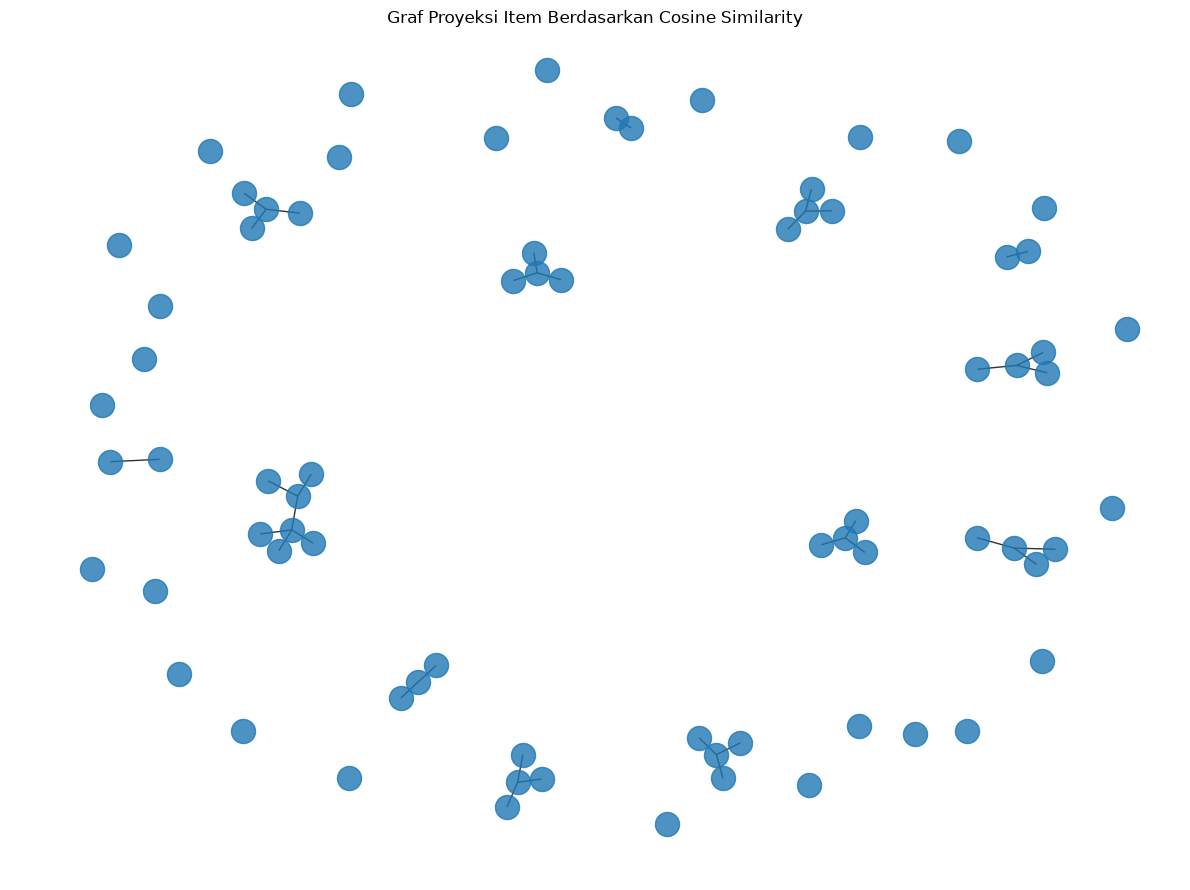

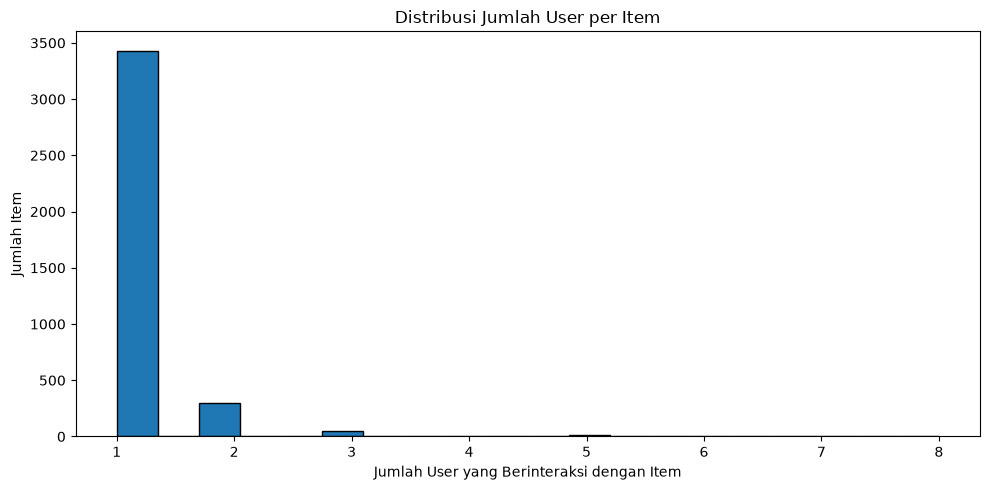

In [50]:
# MEMBENTUK VSM ITEM-USER

# Baris = Item, kolom = User
# Nilai 1 menunjukkan Item pernah diinteraksikan oleh User
item_user_matrix = pd.crosstab(
    df_sub["itemid"],
    df_sub["visitorid"]
)

# Mengubah nilai menjadi biner 0 dan 1
item_user_matrix = (item_user_matrix > 0).astype(int)

print("\n=== KARAKTERISTIK VSM ITEM ===")
print("Dimensi matriks :", item_user_matrix.ndim)
print("Shape matriks   :", item_user_matrix.shape)
print("Jumlah Item     :", item_user_matrix.shape[0])
print("Jumlah User     :", item_user_matrix.shape[1])
print("Jumlah nilai 1  :", int(item_user_matrix.to_numpy().sum()))
print("Jumlah elemen   :", item_user_matrix.size)

sparsity = 1 - (
    item_user_matrix.to_numpy().sum() / item_user_matrix.size
)

print(f"Sparsity matriks: {sparsity:.4%}")

print("\nContoh matriks VSM Item:")
display(item_user_matrix.iloc[:5, :10])


item_similarity = cosine_similarity(item_user_matrix)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=item_user_matrix.index,
    columns=item_user_matrix.index
)

print("\n=== MATRIKS SIMILARITY ITEM ===")
print("Shape similarity:", item_similarity_df.shape)

display(item_similarity_df.iloc[:5, :5])


# MEMBENTUK GRAF PROYEKSI ITEM DENGAN NETWORKX

# Maksimal 40 Item untuk visualisasi
n_plot = min(40, len(item_user_matrix))
plot_items = item_user_matrix.index[:n_plot]

G_item = nx.Graph()
G_item.add_nodes_from(plot_items)

# Hubungkan setiap Item dengan maksimal 3 Item
# yang memiliki cosine similarity positif tertinggi
for item_id in plot_items:
    scores = item_similarity_df.loc[item_id].drop(
        index=item_id
    )

    # Hanya mempertahankan kemiripan positif
    scores = scores[scores > 0]

    top_neighbors = scores.nlargest(3)

    for neighbor_id, score in top_neighbors.items():
        G_item.add_edge(
            item_id,
            neighbor_id,
            weight=float(score)
        )

print("\n=== KARAKTERISTIK GRAF ITEM ===")
print("Jumlah node     :", G_item.number_of_nodes())
print("Jumlah edge     :", G_item.number_of_edges())
print("Graf terhubung? :", nx.is_connected(G_item))

# Visualisasi graf
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    with_labels=False,
    node_size=300,
    alpha=0.8
)

plt.title("Graf Proyeksi Item Berdasarkan Cosine Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()

# DISTRIBUSI JUMLAH USER PER ITEM

item_user_counts = item_user_matrix.sum(axis=1)

plt.figure(figsize=(10, 5))
plt.hist(item_user_counts, bins=20, edgecolor="black")
plt.title("Distribusi Jumlah User per Item")
plt.xlabel("Jumlah User yang Berinteraksi dengan Item")
plt.ylabel("Jumlah Item")
plt.tight_layout()
plt.show()


### Pembentukan Matriks VSM Item

Berdasarkan hasil pengolahan data, diperoleh **3.806 Item unik dan 3.359 User unik**. Matriks VSM Item memiliki dimensi sebanyak 2 dengan `shape` sebesar **(3806, 3359)**. Artinya, matriks terdiri atas 3.806 baris yang mewakili Item dan 3.359 kolom yang mewakili User. Setiap Item direpresentasikan sebagai vektor dengan 3.359 fitur yang menunjukkan pola interaksinya terhadap User.

Jumlah keseluruhan elemen matriks adalah 12.784.354, dengan 4.307 elemen bernilai 1. Nilai tersebut menunjukkan jumlah pasangan Item–User yang memiliki interaksi pada sampel data. Sementara itu, elemen bernilai 0 menunjukkan pasangan Item–User yang tidak memiliki interaksi dalam sampel tersebut.

### Karakteristik Matriks VSM Item

Berdasarkan hasil perhitungan, matriks VSM Item memiliki tingkat *sparsity* sebesar **99,9663%**. Nilai tersebut menunjukkan bahwa hampir seluruh pasangan Item–User dalam matriks tidak memiliki interaksi. Dengan kata lain, setiap Item hanya berinteraksi dengan sebagian kecil dari keseluruhan User yang terdapat dalam data.

Karakteristik tersebut juga terlihat pada histogram distribusi jumlah User per Item. Histogram menunjukkan bahwa sebagian besar Item hanya memiliki satu User yang berinteraksi dengannya. Sebagian Item lainnya memiliki dua User, sedangkan hanya sedikit Item yang memiliki tiga User atau lebih. Berdasarkan grafik, jumlah User yang berinteraksi dengan satu Item mencapai sekitar 3.400 Item, sementara jumlah Item dengan interaksi dari lebih banyak User jauh lebih sedikit.

### Perhitungan Cosine Similarity Antar-Item

Hasil perhitungan menghasilkan matriks similarity dengan `shape` sebesar **(3806, 3806)**. Matriks tersebut membandingkan setiap Item dengan seluruh Item lainnya. Nilai cosine similarity berada pada rentang 0 hingga 1 karena matriks VSM menggunakan nilai biner nonnegatif. Nilai yang semakin mendekati 1 menunjukkan pola interaksi User yang semakin mirip, sedangkan nilai 0 menunjukkan bahwa kedua Item tidak memiliki User yang sama dalam representasi vektornya. Nilai diagonal sebesar 1 menunjukkan bahwa setiap Item memiliki kemiripan sempurna dengan dirinya sendiri.

Berdasarkan contoh matriks similarity yang ditampilkan, beberapa pasangan Item memiliki nilai kemiripan 0. Kondisi ini sesuai dengan karakteristik matriks VSM yang sangat *sparse*, karena sebagian besar Item hanya memiliki sedikit User yang berinteraksi dengannya. Dengan demikian, peluang dua Item memiliki User yang sama pada sampel data relatif terbatas.

### Visualisasi Graf Proyeksi Item Menggunakan NetworkX

 Untuk menjaga keterbacaan visualisasi, pemilihan Item untuk pembentukan graf dibatasi hingga 40 Item awal. Setiap Item kemudian dihubungkan dengan maksimal tiga tetangga teratas yang memiliki nilai similarity positif.

Berdasarkan hasil yang diperoleh, graf memiliki **74 simpul dan 35 sisi** serta tidak terhubung (*disconnected graph*). Jumlah simpul yang mencapai 74 terjadi karena selain 40 Item awal, graf juga memasukkan Item lain yang menjadi tetangga terpilih dari Item awal tersebut. Dengan demikian, jumlah simpul graf dapat melebihi batas awal 40 Item.

Jumlah sisi yang relatif sedikit menunjukkan bahwa hubungan kemiripan positif yang terbentuk pada graf visualisasi masih terbatas. Beberapa Item membentuk kelompok kecil yang saling terhubung, sedangkan Item lainnya tidak memiliki sisi yang menghubungkannya dengan Item lain pada graf. Status graf yang tidak terhubung menunjukkan bahwa tidak semua simpul berada dalam satu komponen yang sama.

## Nomor 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!


Berdasarkan hasil eksplorasi pada nomor 4 dan 5, dilakukan perbandingan antara proyeksi User dan proyeksi Item untuk mengetahui pendekatan yang lebih efektif dan efisien. Kedua proyeksi menggunakan 5.000 baris data yang sama, tetapi memiliki sudut pandang yang berbeda. Proyeksi User merepresentasikan User berdasarkan Item yang pernah diinteraksikan, sedangkan proyeksi Item merepresentasikan Item berdasarkan User yang pernah berinteraksi dengannya.

| Karakteristik | Proyeksi User | Proyeksi Item |
|---|---:|---:|
| Jumlah baris data | 5.000 | 5.000 |
| Jumlah User unik | 3.359 | 3.359 |
| Jumlah Item unik | 3.806 | 3.806 |
| Dimensi matriks VSM | 2 | 2 |
| Shape matriks VSM | (3359, 3806) | (3806, 3359) |
| Shape matriks similarity | (3359, 3359) | (3806, 3806) |
| Jumlah nilai 1 | 4.307 | 4.307 |
| Jumlah seluruh elemen | 12.784.354 | 12.784.354 |
| Sparsity | 99,9663% | 99,9663% |
| Jumlah node pada graf visualisasi | 40 | 74 |
| Jumlah edge pada graf visualisasi | 10 | 35 |
| Kondisi graf | Tidak terhubung | Tidak terhubung |

Berdasarkan tabel tersebut, keduanya memiliki tingkat sparsity yang sama, yaitu 99,9663%. Hal ini disebabkan oleh penggunaan data interaksi yang sama. Perbedaannya terletak pada orientasi matriks dan jumlah simpul yang dibandingkan dalam matriks similarity.

Dari segi efisiensi komputasi, **proyeksi User lebih efisien** karena matriks similarity berukuran (3359, 3359), sedangkan proyeksi Item berukuran (3806, 3806). Dengan jumlah simpul yang lebih sedikit, proyeksi User membutuhkan lebih sedikit perhitungan similarity dan relatif lebih hemat memori.

Sementara itu, jumlah node dan edge pada graf visualisasi tidak dapat langsung digunakan untuk menentukan proyeksi yang lebih efisien karena visualisasi dibentuk berdasarkan pemilihan tetangga dengan similarity positif. Jumlah tersebut juga dipengaruhi oleh pola hubungan yang terbentuk.


## Nomor 7 Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python   

### (a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!  

In [51]:
sim = user_similarity_df.to_numpy().copy()
np.fill_diagonal(sim, 0)

# Cari user dengan jumlah pasangan similarity positif terbanyak
jumlah_positif = (sim > 0).sum(axis=1)
idx_acuan = np.argmax(jumlah_positif)

user_acuan = user_similarity_df.index[idx_acuan]

print("User acuan:", user_acuan)
print("Jumlah user dengan similarity positif:",
      jumlah_positif[idx_acuan])

# Ambil 5 user dengan similarity tertinggi
hasil = (
    user_similarity_df.loc[user_acuan]
    .drop(user_acuan)
    .sort_values(ascending=False)
    .head(5)
)

hasil_df = hasil.reset_index()
hasil_df.columns = ["user_mirip", "similarity"]
hasil_df.insert(0, "user_acuan", user_acuan)

print(hasil_df.to_string(index=False))


User acuan: 163561
Jumlah user dengan similarity positif: 21
 user_acuan  user_mirip  similarity
     163561      938116    0.218218
     163561      840378    0.218218
     163561     1027708    0.218218
     163561     1028073    0.218218
     163561       64595    0.218218


Berdasarkan hasil perhitungan cosine similarity pada proyeksi graf User, User 163561 memiliki 21 user lain dengan nilai similarity positif. Lima user dengan nilai similarity tertinggi adalah 938116, 840378, 1027708, 1028073, dan 64595, masing-masing dengan nilai 0,218218. Nilai yang sama menunjukkan tingkat kemiripan tertinggi yang diperoleh oleh kelima user tersebut terhadap User 163561 berdasarkan pola interaksi item.

### (b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

In [52]:
with driver.session(database="neo4j") as session:
    for _, row in hasil_df.iterrows():
        session.run("""
            MATCH (u1:Visitor {visitorId: $user1})
            MATCH (u2:Visitor {visitorId: $user2})
            MERGE (u1)-[r:SIMILAR]-(u2)
            SET r.similarity = $similarity
            SET r.user_acuan = $user1
        """,
        user1=int(row["user_acuan"]),
        user2=int(row["user_mirip"]),
        similarity=float(row["similarity"])
        )

print("Lima relasi similarity berhasil diproses.")


Lima relasi similarity berhasil diproses.


In [53]:
query = """
MATCH (u1:Visitor)-[r:SIMILAR]-(u2:Visitor)
WHERE r.user_acuan = 163561
RETURN
    r.user_acuan AS user_acuan,
    u2.visitorId AS user_mirip,
    round(r.similarity, 6) AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(query)
    hasil_cypher = pd.DataFrame([record.data() for record in result])

display(hasil_cypher)


,user_acuan,user_mirip,similarity
0,163561,163561,0.218218
1,163561,938116,0.218218
2,163561,163561,0.218218
3,163561,64595,0.218218
4,163561,1028073,0.218218


## Nomor 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

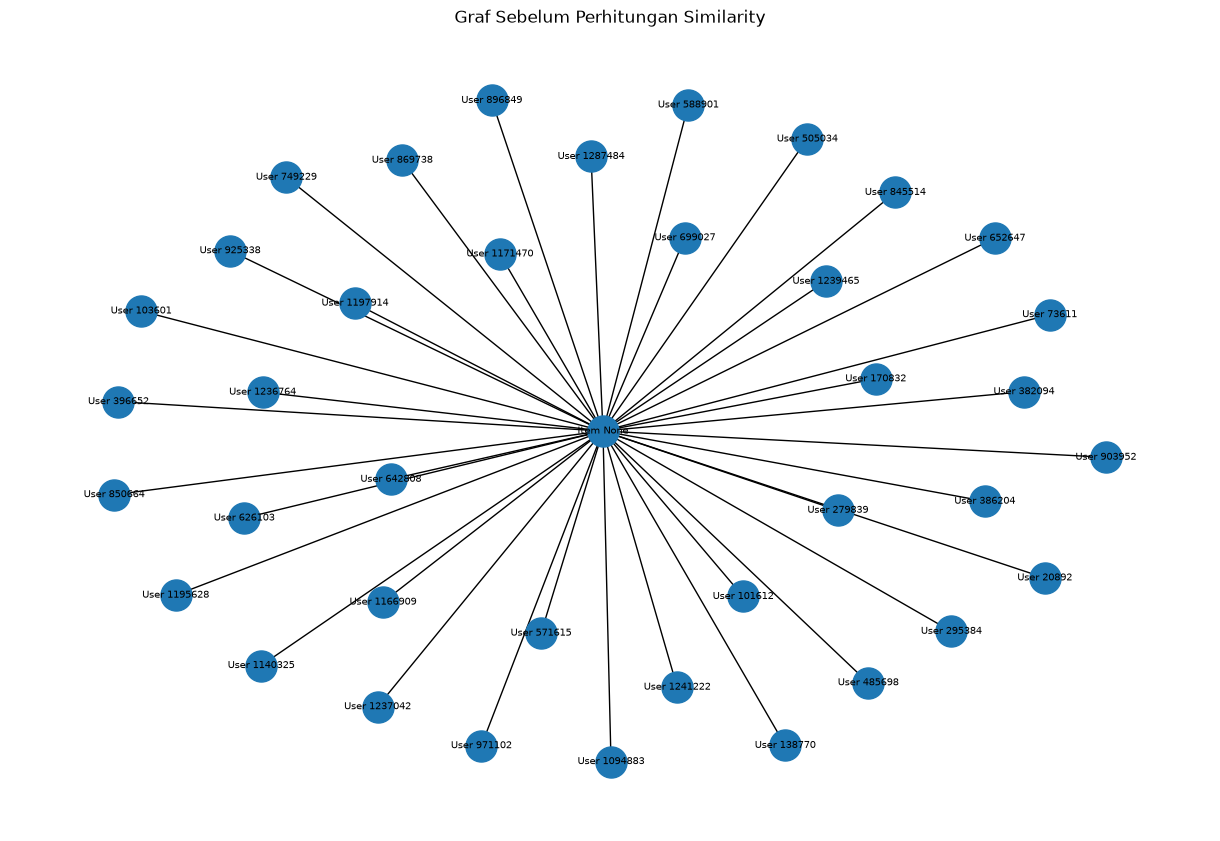

In [54]:
query_sebelum = """
MATCH (u:Visitor)-[:VIEWED]->(i:Item)
RETURN u.visitorId AS user, i.itemid AS item
LIMIT 100
"""

with driver.session(database="neo4j") as session:
    records = [r.data() for r in session.run(query_sebelum)]

G_sebelum = nx.Graph()

for r in records:
    G_sebelum.add_edge(
        f"User {r['user']}",
        f"Item {r['item']}"
    )

plt.figure(figsize=(12, 8))
nx.draw(
    G_sebelum,
    with_labels=True,
    node_size=500,
    font_size=7
)
plt.title("Graf Sebelum Perhitungan Similarity")
plt.show()


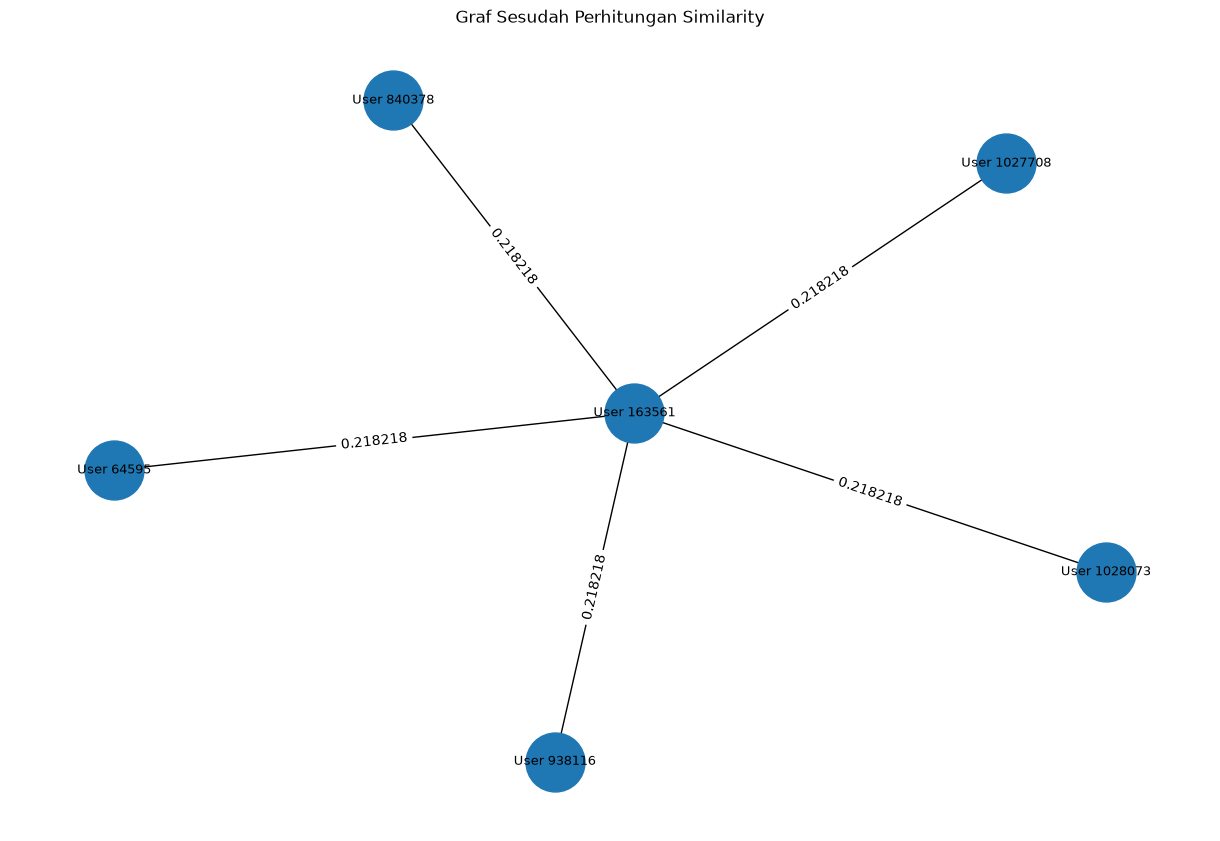

Jumlah node: 6
Jumlah relasi: 5


In [55]:
query_sesudah = """
MATCH (u1:Visitor)-[r:SIMILAR]-(u2:Visitor)
WHERE r.user_acuan = 163561
  AND u1.visitorId = r.user_acuan
RETURN
    u1.visitorId AS user1,
    u2.visitorId AS user2,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    records = [r.data() for r in session.run(query_sesudah)]

G_sesudah = nx.Graph()

for r in records:
    G_sesudah.add_edge(
        f"User {r['user1']}",
        f"User {r['user2']}",
        weight=r["similarity"]
    )

pos = nx.spring_layout(G_sesudah, seed=42)

plt.figure(figsize=(12, 8))
nx.draw(
    G_sesudah, pos,
    with_labels=True,
    node_size=1800,
    font_size=9
)

edge_labels = {
    edge: f"{weight:.6f}"
    for edge, weight in nx.get_edge_attributes(
        G_sesudah, "weight"
    ).items()
}
nx.draw_networkx_edge_labels(
    G_sesudah, pos,
    edge_labels=edge_labels
)

plt.title("Graf Sesudah Perhitungan Similarity")
plt.show()

print("Jumlah node:", G_sesudah.number_of_nodes())
print("Jumlah relasi:", G_sesudah.number_of_edges())


Graf sebelum perhitungan similarity menunjukkan hubungan interaksi antara User dan Item berdasarkan relasi VIEWED. Setelah perhitungan cosine similarity dan penyimpanan hasil ke Neo4j, graf menampilkan User 163561 yang terhubung dengan lima user paling mirip, yaitu 1028073, 938116, 64595, 1027708, dan 840378. Kelima relasi memiliki nilai similarity sebesar 0,218218. Dengan demikian, graf sesudah perhitungan terdiri dari 6 node User dan 5 relasi SIMILAR. Perubahan ini menunjukkan bahwa graf tidak hanya merepresentasikan interaksi pengguna dengan item, tetapi juga hubungan kemiripan antar pengguna berdasarkan pola interaksinya.

# Soal-soal 2.2

## Nomor 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi)

### (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

In [56]:
test_users = set(df_p2["visitorid"].unique())

eligible_users = [
    u for u in user_item_matrix.index
    if u in test_users
]

rng = np.random.default_rng(42)
user_acuan = rng.choice(eligible_users)

print("User terpilih:", user_acuan)

# Cari 5 tetangga terdekat (k = 5)
similarities = pd.Series(
    user_similarity[
        user_item_matrix.index.get_loc(user_acuan)
    ],
    index=user_item_matrix.index
).drop(user_acuan)

neighbors = similarities.nlargest(5)

print("\n5 tetangga terdekat:")
display(neighbors.rename("similarity").to_frame())

# Hitung skor rekomendasi berdasarkan interaksi tetangga
neighbor_matrix = user_item_matrix.loc[neighbors.index]
scores = neighbor_matrix.T.dot(neighbors)

# Hilangkan item yang sudah pernah dilihat user
seen_items = user_item_matrix.loc[user_acuan]
scores = scores[seen_items == 0]

# Ambil 5 item dengan skor tertinggi
recommendations = scores.nlargest(5)

hasil_rekomendasi = pd.DataFrame({
    "itemid": recommendations.index,
    "score": recommendations.values
})

print("\n5 rekomendasi item:")
display(hasil_rekomendasi)


User terpilih: 58455

5 tetangga terdekat:


,similarity
visitorid,
463575,0.57735
283,0.00000
476,0.00000
2219,0.00000
2360,0.00000



5 rekomendasi item:


,itemid,score
0,339305,0.57735
1,407669,0.57735
2,466,0.00000
3,502,0.00000
4,516,0.00000


Berdasarkan proses pemilihan user secara acak dengan menggunakan random_state = 42, diperoleh user dengan ID 58455 sebagai user yang akan diberikan rekomendasi. Selanjutnya, metode KNN digunakan untuk mencari lima tetangga terdekat berdasarkan nilai cosine similarity dari matriks interaksi user-item.

Hasil perhitungan menunjukkan bahwa user dengan ID 463575 memiliki nilai kemiripan tertinggi, yaitu sebesar 0,57735. Sementara itu, empat user lainnya, yaitu 283, 476, 2219, dan 2360, memiliki nilai kemiripan sebesar 0. Nilai tersebut menunjukkan bahwa berdasarkan representasi interaksi yang digunakan, keempat user tersebut tidak memiliki kemiripan positif dengan user 58455. Dengan demikian, meskipun lima tetangga telah dipilih sesuai parameter \(k=5\), hanya satu tetangga yang memberikan kontribusi positif terhadap proses rekomendasi.

### (b) berikan 3 item yang diiklankan untuk $k = 5$ pada penentuan KNN nya! 

In [57]:
top3_rekomendasi = hasil_rekomendasi.head(3).copy()
top3_rekomendasi.insert(0, "peringkat", [1, 2, 3])

print("User terpilih:", user_acuan)
print("3 item rekomendasi untuk k = 5:")
display(top3_rekomendasi)


User terpilih: 58455
3 item rekomendasi untuk k = 5:


,peringkat,itemid,score
0,1,339305,0.57735
1,2,407669,0.57735
2,3,466,0.00000


Hasil perhitungan menghasilkan lima rekomendasi item, yaitu item 339305 dan 407669 yang masing-masing memiliki skor 0,57735, serta item 466, 502, dan 516 yang memiliki skor 0. Berdasarkan hasil tersebut, tiga rekomendasi teratas yang ditampilkan untuk user 58455 adalah item 339305, 407669, dan 466.

Item 339305 dan 407669 memperoleh skor tertinggi karena mendapatkan kontribusi dari tetangga dengan nilai kemiripan positif. Sebaliknya, item 466 memiliki skor 0, sehingga posisinya sebagai rekomendasi ketiga tidak menunjukkan adanya dukungan kemiripan positif dari tetangga yang digunakan. Item 466 tetap muncul karena sistem mengambil lima item dengan skor tertinggi, termasuk item yang memiliki skor sama-sama nol.

## Nomor 2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a) Hit@5

(b) NDCG@5

In [58]:
# Item yang benar-benar diinteraksikan user pada periode testing
relevant_items = set(
    df_p2.loc[
        df_p2["visitorid"] == user_acuan,
        "itemid"
    ].unique()
)

# Daftar 5 item rekomendasi
top5 = list(recommendations.index)

# Hit@5
hits = [1 if item in relevant_items else 0 for item in top5]
hit_at_5 = int(sum(hits) > 0)

# NDCG@5
dcg = sum(
    hit / np.log2(rank + 2)
    for rank, hit in enumerate(hits)
)

ideal_hits = min(len(relevant_items), 5)
idcg = sum(
    1 / np.log2(rank + 2)
    for rank in range(ideal_hits)
)

ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print("User:", user_acuan)
print("Jumlah item relevan di testing:", len(relevant_items))
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


User: 58455
Jumlah item relevan di testing: 1
Hit@5: 0
NDCG@5: 0.0


Evaluasi dilakukan dengan membandingkan lima item rekomendasi dengan item yang benar-benar diinteraksikan oleh user 58455 pada periode testing. Berdasarkan hasil evaluasi, terdapat satu item relevan pada data testing, tetapi tidak ada satu pun dari lima item rekomendasi yang sesuai dengan item tersebut. Dengan demikian, diperoleh nilai Hit@5 sebesar 0, yang menunjukkan bahwa tidak terdapat item relevan yang berhasil ditemukan dalam lima rekomendasi teratas. Sementara itu, nilai NDCG@5 sebesar 0,0 menunjukkan bahwa tidak ada item relevan dalam daftar rekomendasi yang berkontribusi pada perhitungan nilai relevansi berdasarkan posisi item. Hasil ini menunjukkan bahwa rekomendasi yang dihasilkan oleh metode KNN untuk user 58455 belum sesuai dengan interaksi aktualnya pada periode testing.